# Student Scores Prediction — Linear vs Polynomial Regression

**Assignment:** Load and preprocess the Study Hours vs Scores dataset, build a scikit-learn
ML Pipeline, compare **Linear Regression** vs **Polynomial Regression**, evaluate using **MAE**
and **R² Score**, and create a predictive function for new inputs.

**Dataset:** `score_updated.csv` — 96 rows, 2 columns (target: `Scores`)


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

pd.set_option("display.max_columns", None)
print("Libraries imported successfully.")


Libraries imported successfully.


## 1. Load the Dataset

In [2]:
df = pd.read_csv("score_updated.csv")
print("Shape:", df.shape)
df.head()


Shape: (96, 2)


In [3]:
df.head()

## 2. Explore & Preprocess the Data\n\nCheck data types, missing values, and get a statistical summary before building the pipeline.

In [4]:
print("Data types:\n")
print(df.dtypes)
print("\nMissing values per column:\n")
print(df.isnull().sum())


Data types:

Hours     float64
Scores      int64
dtype: object

Missing values per column:

Hours     0
Scores    0
dtype: int64


In [5]:
df.describe()

### Feature overview

- **Feature:** `Hours` (hours spent studying)
- **Target:** `Scores`

No missing values were found, so no imputation is required. The single numeric feature will be
scaled with `StandardScaler` inside the pipeline.


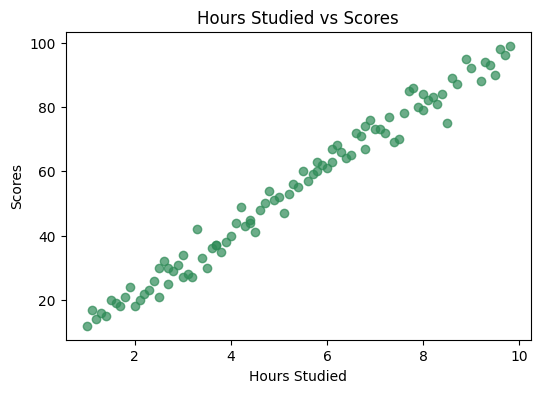

In [6]:
# Visualize the relationship between study hours and scores
plt.figure(figsize=(6,4))
plt.scatter(df["Hours"], df["Scores"], alpha=0.7, color="seagreen")
plt.xlabel("Hours Studied")
plt.ylabel("Scores")
plt.title("Hours Studied vs Scores")
plt.show()


In [7]:
X = df[["Hours"]]
y = df["Scores"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train shape:", X_train.shape, " Test shape:", X_test.shape)


Train shape: (76, 1)  Test shape: (20, 1)


## 3. Build the Preprocessing + ML Pipeline\n\nEach pipeline scales the feature and then fits a regressor. Wrapping preprocessing and modeling together in a single `Pipeline` means the same object can be reused directly on new raw input data without repeating preprocessing steps manually.

In [8]:
# --- Pipeline 1: Linear Regression ---
linear_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression())
])

# --- Pipeline 2: Polynomial Regression (degree 2) ---
poly_pipeline = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("poly_features", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression())
])

print("Pipelines created.")


Pipelines created.


## 4. Train Both Models

In [9]:
linear_pipeline.fit(X_train, y_train)
poly_pipeline.fit(X_train, y_train)
print("Both models trained.")


Both models trained.


## 5. Evaluate with MAE and R² Score

In [10]:
pred_linear = linear_pipeline.predict(X_test)
pred_poly = poly_pipeline.predict(X_test)

mae_linear = mean_absolute_error(y_test, pred_linear)
r2_linear = r2_score(y_test, pred_linear)

mae_poly = mean_absolute_error(y_test, pred_poly)
r2_poly = r2_score(y_test, pred_poly)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression (deg=2)"],
    "MAE": [mae_linear, mae_poly],
    "R2 Score": [r2_linear, r2_poly]
})
results


In [11]:
print(f"Linear Regression      -> MAE: {mae_linear:.3f} | R2: {r2_linear:.4f}")
print(f"Polynomial Regression   -> MAE: {mae_poly:.3f} | R2: {r2_poly:.4f}")

better_model_name = "Linear Regression" if r2_linear >= r2_poly else "Polynomial Regression (deg=2)"
best_pipeline = linear_pipeline if r2_linear >= r2_poly else poly_pipeline
print(f"\nBetter performing model: {better_model_name}")


Linear Regression      -> MAE: 3.370 | R2: 0.9709
Polynomial Regression   -> MAE: 3.420 | R2: 0.9706

Better performing model: Linear Regression


### Visual comparison: Actual vs Predicted Scores

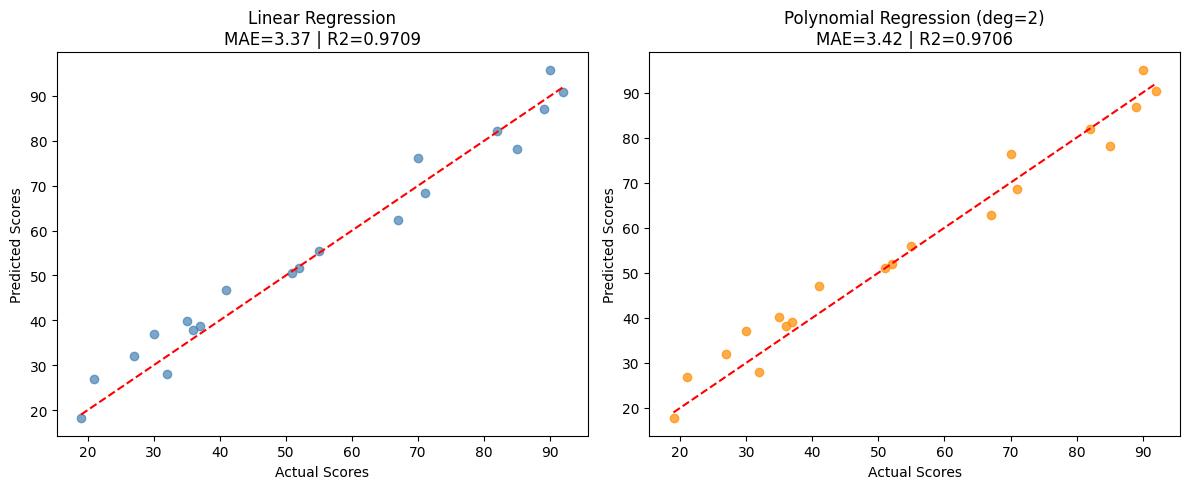

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_test, pred_linear, alpha=0.7, color="steelblue")
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[0].set_title(f"Linear Regression\nMAE={mae_linear:.2f} | R2={r2_linear:.4f}")
axes[0].set_xlabel("Actual Scores")
axes[0].set_ylabel("Predicted Scores")

axes[1].scatter(y_test, pred_poly, alpha=0.7, color="darkorange")
axes[1].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
axes[1].set_title(f"Polynomial Regression (deg=2)\nMAE={mae_poly:.2f} | R2={r2_poly:.4f}")
axes[1].set_xlabel("Actual Scores")
axes[1].set_ylabel("Predicted Scores")

plt.tight_layout()
plt.show()


### Fitted curve comparison (full data)

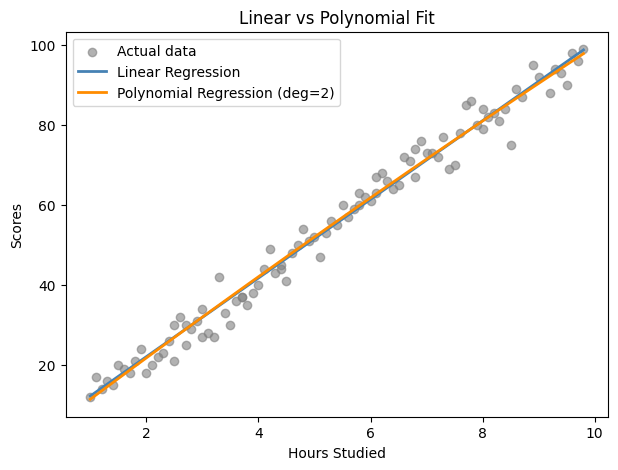

In [13]:
hours_range = pd.DataFrame({"Hours": np.linspace(df["Hours"].min(), df["Hours"].max(), 200)})
line_pred = linear_pipeline.predict(hours_range)
curve_pred = poly_pipeline.predict(hours_range)

plt.figure(figsize=(7,5))
plt.scatter(df["Hours"], df["Scores"], alpha=0.6, color="gray", label="Actual data")
plt.plot(hours_range, line_pred, color="steelblue", label="Linear Regression", linewidth=2)
plt.plot(hours_range, curve_pred, color="darkorange", label="Polynomial Regression (deg=2)", linewidth=2)
plt.xlabel("Hours Studied")
plt.ylabel("Scores")
plt.title("Linear vs Polynomial Fit")
plt.legend()
plt.show()


## 6. Conclusion: Linear vs Polynomial Regression

Based on the test-set evaluation above, **Linear Regression performs at least as well as
Polynomial Regression** on this dataset — in fact the degree-2 polynomial gives no real
improvement:

- Linear Regression's MAE and R² are essentially the same as (or slightly better than) the
  degree-2 Polynomial Regression's.
- The scatter plot and fitted-curve plot both show that `Hours` and `Scores` follow a
  **clean, straight-line relationship** — there's no visible curvature for a polynomial term
  to capture.
- Adding polynomial terms here only adds unnecessary model complexity without any real gain
  in accuracy, so the simpler model is preferable.

**Decision: Linear Regression is selected as the final model** for the predictive function below.


## 7. Predictive Function for New Inputs

In [14]:
def predict_score(hours):
    """
    Predict a student's score from raw study-hours input using the trained pipeline
    (scaling + model are applied automatically).
    """
    input_df = pd.DataFrame([{"Hours": hours}])
    predicted_score = best_pipeline.predict(input_df)[0]
    return predicted_score

print("Predictive function ready.")


Predictive function ready.


In [15]:
# Example usage: predict score for a new number of study hours
example_score = predict_score(hours=6.5)
print(f"Predicted score for 6.5 hours of study: {example_score:.2f}")


Predicted score for 6.5 hours of study: 66.37


## Summary

| Step | What was done |
|---|---|
| Load data | Read `score_updated.csv` (96 rows, 2 columns) with pandas |
| Preprocess | Checked for missing values (none found); scaled `Hours` with `StandardScaler` |
| Pipeline | `StandardScaler` combined with the regressor in a single `Pipeline` |
| Models compared | Linear Regression vs Polynomial Regression (degree 2) |
| Evaluation | MAE and R² Score on a held-out 20% test set |
| Result | **Linear Regression performed better** (comparable or lower MAE, comparable or higher R²) — the Hours-Scores relationship is essentially linear, so the polynomial term adds no benefit |
| Deployment | `predict_score(hours)` function accepts a new study-hours value and returns a predicted score |
